In [1]:
!pip install --upgrade pip --quiet

In [2]:
!pip install --upgrade numpy --quiet

In [3]:
!pip install --upgrade pandas --quiet

In [4]:
!pip install --upgrade scipy --quiet

In [5]:
!pip install --upgrade statsmodels --quiet

In [6]:
!pip install --upgrade scikit-learn --quiet

In [7]:
!pip install --upgrade matplotlib --quiet

In [8]:
!pip install --upgrade seaborn --quiet

In [9]:
import numpy as np

In [10]:
import pandas as pd

In [11]:
import matplotlib.pyplot as plt

In [12]:
import seaborn as sns

In [13]:
import statsmodels.formula.api as smf

In [14]:
from sklearn.linear_model import LogisticRegression

In [15]:
from sklearn.neighbors import NearestNeighbors

In [16]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [17]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

In [18]:
from sklearn.model_selection import cross_val_predict

In [19]:
from sklearn.metrics import roc_auc_score

In [20]:
def diferenca_de_medias(dados, tratamento, resultado):
    """Diferença simples de médias entre tratados e controles."""
    g = dados.groupby(tratamento)[resultado].agg(["count", "mean"])
    dif = g.loc[1, "mean"] - g.loc[0, "mean"]
    return g, dif

In [21]:
def love_plot(smd_antes, smd_depois, titulo="Love plot"):
    """Compara SMDs antes e depois do ajuste."""
    fig, ax = plt.subplots(figsize=(7, 4))
    y = np.arange(len(smd_antes))
    ax.scatter(smd_antes["SMD"].abs(), y, label="antes", color="#d93636", s=60)
    ax.scatter(smd_depois["SMD"].abs(), y, label="depois", color="#2e9e5b", s=60)
    ax.axvline(0.1, color="grey", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(smd_antes["covariável"])
    ax.set_xlabel("|SMD| (diferença padronizada de médias)")
    ax.set_title(titulo)
    ax.legend()
    plt.tight_layout();

# Avaliação de Políticas Públicas com Dados 📊

<p style="text-align: right">Prof. <a href="https://www.linkedin.com/in/heliomacedofilho/">Hélio Bomfim de Macêdo Filho</a><br />
<a href="https://www.idp.edu.br/mestrado/profissional-em-ciencia-de-dados">Mestrado em Administração Pública:<br />Ciência de Dados e Inteligência Artificial no Setor Público</a></p>

## Módulo 03 - Seleção nos Observáveis: Pareamento e Escore de Propensão

## Sumário
<ul>
    <li>A Hipótese que Tudo Sustenta</li>
    <ul>
        <li>Ignorabilidade e Suporte Comum</li>
    </ul>
    <li>Subclassificação e Pareamento Exato</li>
    <li>Pareamento por Vizinho Mais Próximo</li>
    <li>Wrap Up</li>
    <li>O Escore de Propensão</li>
    <ul>
        <li>Estimação por Regressão Logística</li>
        <li>Estimação por <i>Machine Learning</i> e Seus Perigos</li>
    </ul>
    <li>Métodos Baseados no Escore: Pareamento, Estratos e IPW</li>
    <li>Diagnósticos e a Crítica ao Pareamento pelo Escore</li>
    <li>Extra! 🗞️ Estimadores duplamente robustos</li>
</ul>

👉 Leitura de apoio desta aula (todas gratuitas online):

- FACURE, M. *<a href="https://matheusfacure.github.io/python-causality-handbook/">Causal Inference for the Brave and True</a>*, caps. 11 e 12.
- CUNNINGHAM, S. *<a href="https://mixtape.scunning.com/05-matching_and_subclassification">Causal Inference: The Mixtape</a>*, cap. 5.
- HERNÁN, M.; ROBINS, J. *<a href="https://static1.squarespace.com/static/675db8b0dd37046447128f5f/t/677676888e31cc50c2c33877/1735816881944/hernanrobins_WhatIf_2jan25.pdf">Causal Inference: What If</a>*, caps. 12 e 15.
- DE BRAUW, A. et al. (2015). <a href="https://www.sciencedirect.com/science/article/pii/S0305750X1500025X">The Impact of Bolsa Família on Schooling</a>. *World Development*, 70.

🚨 **Antes de começar — arquivo de dados.** 🎲

Usaremos a Avaliação de Impacto do Bolsa Família (AIBF II), módulo de educação.

👉 Os microdados são públicos e desidentificados. Distribuídos pela 
- Secretaria de Avaliação, Gestão da Informação e Cadastro Único (Sagicad) do
- Ministério do Desenvolvimento e Assistência Social, Família e Combate à Fome (MDS). 

Fonte: <a href="https://aplicacoes.mds.gov.br/sagicad/pesquisas/lista-s.php?stk=ano&i=2012">Pesquisa de Avaliação de Impacto do Programa Bolsa Família (AIBF II)</a>

Especificamente, os arquivos
- `aula03_completo.csv`
    - (microdados da AIBF II — Avaliação de Impacto do Bolsa Família) e
- `pscores_completo.csv`
    - (escores de propensão oficiais calculados pela equipe do <i>The International Food Policy Research Institute</i> - IFPRI).

## Recapitulando o Módulo 02 🔁

👉 Onde estamos nas três primeiras aulas:

- **Módulo 01** — o problema:
    - a diferença simples de médias mistura
        - o **efeito do tratamento** com
        - o **viés de seleção**.
- **Módulo 02** — uma solução:
    - o **sorteio** zera o viés de seleção,
        - porque torna o tratamento independente dos resultados potenciais.

🚨 No entanto, o gestor público quase nunca pode sortear.

Não se sorteia 
- quem recebe aposentadoria,
- quem mora perto de um posto de saúde,
- quem foi atingido por uma seca. 

No **Bolsa Família**, não foi distribuído por sorteio: 
- as famílias
    - se inscreveram,
    - foram avaliadas, e
    - as mais pobres entraram.

👉 A pergunta deste módulo:

> Sem poder sortear, é possível estimar o efeito causal de um programa a partir de dados **observacionais**?

A resposta é "sim, **sob uma condição**" 
- e a aula inteira é sobre entender
    - essa condição,
    - os métodos que ela habilita, e
    - o que ela **não** resolve.

## A Hipótese que Tudo Sustenta

### O Fio Condutor: a AIBF II 🇧🇷

Voltamos ao *dataset* do Módulo 01 
- a **Avaliação de Impacto do Bolsa Família (AIBF II)**, módulo de educação. 

Mas agora vamos usá-lo de outro modo.

ℹ️ A AIBF II tem um desenho amostral com **três grupos**, definidos na linha de base:

- **Beneficiários**:
    - domicílios que recebiam o Bolsa Família;
- **Controle "cadastrado" (C1)**: 
    - domicílios inscritos no CadÚnico, mas que *não* recebiam o benefício;
- **Controle "não-cadastrado" (C2)**
    - domicílios fora do CadÚnico.

👉 Este caderno usa beneficiários e o controle C1.

- A razão é importante e já é conteúdo da aula — voltaremos a ela.

👉 Vamos carregar os dados.

In [22]:
aibf = pd.read_csv("data/aula03_completo.csv")
aibf.shape

(56367, 28)

In [23]:
aibf.head()

,cod_dtm,s00a1,s02af,age,s02ad,s02a17,s02a21,s02a10,s02a5,s03a2,...,source,educ_chefe,n_moradores,n_familias,n_comodos,n_dormitorios,n_banheiros,agua_canalizada,mae_resp_le,estrato_amostral
0,1,11.0,52.0,52.232717,1.0,3.0,4.0,2.0,1.0,5.0,...,1.0,NaN,4.0,1.0,4.0,1.0,0.0,NaN,2.0,beneficiario
1,1,11.0,33.0,33.911020,2.0,2.0,4.0,1.0,2.0,3.0,...,1.0,NaN,4.0,1.0,4.0,1.0,0.0,NaN,2.0,beneficiario
2,1,11.0,10.0,10.225873,1.0,2.0,NaN,2.0,3.0,3.0,...,1.0,NaN,4.0,1.0,4.0,1.0,0.0,NaN,2.0,beneficiario
3,1,11.0,8.0,8.399726,1.0,2.0,NaN,2.0,3.0,3.0,...,1.0,NaN,4.0,1.0,4.0,1.0,0.0,NaN,2.0,beneficiario
4,2,11.0,63.0,63.611225,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,3.0,5.0,1.0,6.0,2.0,1.0,1.0,1.0,NaN


👉 Como no Módulo 01, o tratamento é definido no **domicílio**: 
- a criança é tratada se vive num domicílio com algum titular do cartão do Bolsa Família.

In [24]:
trat_dom = (aibf.groupby("cod_dtm")["s02a10"]
                .apply(lambda s: int((s == 1).any()))
                .rename("D"))
aibf = aibf.merge(trat_dom, on="cod_dtm", how="left")
aibf["D"].value_counts()

D
1    34437
0    21930
Name: count, dtype: int64

Algumas variáveis que vamos usar:

| Coluna | Papel | Significado |
|---|---|---|
| `D` | tratamento | domicílio recebe o Bolsa Família |
| `p_attend7` | desfecho `Y` | frequência escolar (proporção de dias) |
| `s02af` | covariável | idade da criança |
| `s02ad` | covariável | sexo |
| `s02a17` | covariável | cor/raça |
| `educ_chefe` | covariável | escolaridade do chefe do domicílio |
| `n_moradores` | covariável | número de moradores |
| `n_comodos` | covariável | número de cômodos |
| `n_dormitorios` | covariável | número de dormitórios |
| `agua_canalizada` | covariável | há água canalizada (1 = sim) |

👉 Preparamos a amostra de análise 
- crianças de 6 a 17 anos com desfecho observado e
- as covariáveis numéricas.

In [25]:
aibf["feminino"] = (aibf["s02ad"] == 2).astype(int)
aibf["agua"] = (aibf["agua_canalizada"] == 1).astype(int)

In [26]:
COVARIAVEIS = ["s02af", "feminino", "educ_chefe", "n_moradores",
               "n_comodos", "n_dormitorios", "agua"]

criancas = aibf[aibf["s02af"].between(6, 17) & aibf["p_attend7"].notna()].copy()

In [27]:
dados = criancas.dropna(subset=COVARIAVEIS).rename(columns={"p_attend7": "Y"})

In [28]:
dados.head()

,cod_dtm,s00a1,s02af,age,s02ad,s02a17,s02a21,s02a10,s02a5,s03a2,...,n_familias,n_comodos,n_dormitorios,n_banheiros,agua_canalizada,mae_resp_le,estrato_amostral,D,feminino,agua
6,2,11.0,8.0,8.769336,2.0,1.0,NaN,2.0,3.0,2.0,...,1.0,6.0,2.0,1.0,1.0,1.0,beneficiario,1,1,1
25,7,11.0,17.0,17.494867,1.0,3.0,NaN,2.0,3.0,3.0,...,2.0,7.0,4.0,1.0,1.0,2.0,beneficiario,0,0,1
26,7,11.0,14.0,14.778919,2.0,3.0,NaN,2.0,3.0,3.0,...,2.0,7.0,4.0,1.0,1.0,2.0,beneficiario,0,1,1
27,7,11.0,12.0,12.687201,1.0,3.0,NaN,NaN,3.0,3.0,...,2.0,7.0,4.0,1.0,1.0,2.0,beneficiario,0,0,1
32,8,11.0,16.0,16.870637,1.0,3.0,3.0,2.0,3.0,1.0,...,1.0,5.0,2.0,1.0,1.0,1.0,beneficiario,1,0,1


In [29]:
print("crianças na análise:", len(dados))

crianças na análise: 7805


In [30]:
print("tratadas:", int((dados["D"] == 1).sum()))

tratadas: 5572


In [31]:
print("controle:", int((dados["D"] == 0).sum()))

controle: 2233


### A Diferença Simples (De Novo)

👉 Como no Módulo 01, começamos pela comparação ingênua.

In [32]:
tabela, dif_simples = diferenca_de_medias(dados, "D", "Y")

In [33]:
print(tabela)

   count      mean
D                 
0   2233  0.970192
1   5572  0.963877


In [34]:
print("Diferença simples de médias:", round(dif_simples, 4))

Diferença simples de médias: -0.0063


🚨 A diferença é pequena e **negativa** 
- como no Módulo 01. 

Sabemos o porquê: 
- as famílias beneficiárias são mais pobres, e
- a pobreza puxa a frequência escolar para baixo. 

O viés de seleção contamina a comparação.

👉 A pergunta agora: 
- podemos **corrigir** isso usando as covariáveis observadas?

### Ignorabilidade: a Hipótese-Chave 🗝️

A ideia central da aula é uma hipótese.

Suponha que, **dentro de cada combinação de covariáveis `X`**, o tratamento seja "como se" aleatório:

$$\big(Y(0),\, Y(1)\big) \;\perp\; D \;\mid\; X$$

Isso se chama **ignorabilidade** 
- (ou *seleção nos observáveis*,
- ou *unconfoundedness*).

<details>
  <summary>Por que o nome "ignorabilidade"? 🤔</summary>

O nome se refere ao que pode ser **ignorado**: o **mecanismo de atribuição do tratamento** — o processo que decidiu quem recebeu o Bolsa Família e quem não recebeu.

Numa avaliação observacional, esse mecanismo é a fonte do viés de seleção: as famílias se selecionaram por razões possivelmente ligadas ao desfecho. Em princípio, seria preciso modelá-lo. A hipótese diz que, **uma vez condicionado em `X`**, esse mecanismo deixa de importar para a estimação do efeito — pode ser tratado como se não existisse.

ℹ️ Contraste com o Módulo 02: num RCT, o mecanismo é ignorável **incondicionalmente** — o sorteio garante isso sem nenhum `X`. Na seleção nos observáveis, ele é ignorável **condicionalmente** — só depois de fixar `X`. Por isso o nome completo é *ignorabilidade condicional*, e os sinônimos *unconfoundedness* e *seleção nos observáveis* descrevem a mesma ideia: não sobra confundidor depois de `X`.
</details>

👉 Em palavras: 

- se compararmos famílias **com o mesmo perfil observável**
    - mesma escolaridade do chefe,
    - mesmo tamanho de domicílio,
    - mesma idade da criança,
- então quem recebe e quem não recebe o Bolsa Família seriam comparáveis.

🚨 É a hipótese de **backdoor** do Módulo 01: 
- as covariáveis `X` fecham todos os caminhos de fundo entre `D` e `Y`.

<details>
  <summary>Por que escolhemos o controle "cadastrado" (C1), e não o
  "não-cadastrado" (C2)? 🤔</summary>

Por causa da **ignorabilidade**. Inscrever-se no CadÚnico é uma decisão da
família — quem se inscreve tende a ser mais informado, mais conectado a serviços
públicos, mais mobilizado. Essas são características em parte **não
observáveis**.

Se comparássemos beneficiários com famílias *não-cadastradas*, estaríamos
misturando o efeito do Bolsa Família com o efeito de "ser o tipo de família que
se cadastra". Já beneficiários e controle C1 passaram pelo **mesmo filtro**:
ambos se cadastraram. A hipótese de ignorabilidade fica muito mais plausível —
e é por isso que a literatura (de Brauw et al., 2015) usa esse grupo.
</details>

🚨 **Ignorabilidade é a hipótese mais importante — e mais frágil — da aula.** Por quê?

👉 Ela **não é testável**. 

Não há como verificar nos dados se
- `X` contém todos os confundidores. 

Se sobrar uma causa comum não observada
- a ignorabilidade falha e tudo desaba.
    - (e.g., a motivação dos pais com a educação.)

👉 Diferente do sorteio do Módulo 02, que *garante* a comparabilidade, 
- aqui nós a **assumimos**. 

🚨 Toda a credibilidade vem da qualidade dessa suposição.

### Suporte comum

Há uma segunda condição, mais técnica, chamada **suporte comum** 
- (ou sobreposição,
- ou positividade):

$$0 < P(D=1 \mid X) < 1$$

👉 Em palavras: 
- para todo perfil `X`, é preciso existir **tanto tratados quanto controles**.

Se um certo tipo de família *sempre* recebe o benefício, não há com quem compará-la 
- não há contrafactual nos dados.

ℹ️ Vamos diagnosticar o suporte comum visualmente mais adiante, 
- com o escore de propensão.

## Subclassificação e Pareamento Exato 🗂️

### A Ideia Mais Simples: Comparar Dentro de Estratos 🧱

👉 Se a ignorabilidade vale dado `X`, a receita mais direta é:

1. dividir a amostra em **estratos** de `X`;
2. dentro de cada estrato, calcular a diferença $tratado − controle$;
3. agregar as diferenças com a média ponderada pelo tamanho dos estratos.

Isso é a **subclassificação** (ou estratificação).

👉 Vamos estratificar por sexo $\times$ faixa de escolaridade do chefe.

In [35]:
sub = dados.copy()
sub["esc_chefe_faixa"] = pd.cut(sub["educ_chefe"], 
                                bins=[float('-inf'), 2, 5, float('+inf')],
                                labels=["baixa", "média", "alta"])

In [36]:
sub.head()

,cod_dtm,s00a1,s02af,age,s02ad,s02a17,s02a21,s02a10,s02a5,s03a2,...,n_comodos,n_dormitorios,n_banheiros,agua_canalizada,mae_resp_le,estrato_amostral,D,feminino,agua,esc_chefe_faixa
6,2,11.0,8.0,8.769336,2.0,1.0,NaN,2.0,3.0,2.0,...,6.0,2.0,1.0,1.0,1.0,beneficiario,1,1,1,média
25,7,11.0,17.0,17.494867,1.0,3.0,NaN,2.0,3.0,3.0,...,7.0,4.0,1.0,1.0,2.0,beneficiario,0,0,1,baixa
26,7,11.0,14.0,14.778919,2.0,3.0,NaN,2.0,3.0,3.0,...,7.0,4.0,1.0,1.0,2.0,beneficiario,0,1,1,baixa
27,7,11.0,12.0,12.687201,1.0,3.0,NaN,NaN,3.0,3.0,...,7.0,4.0,1.0,1.0,2.0,beneficiario,0,0,1,baixa
32,8,11.0,16.0,16.870637,1.0,3.0,3.0,2.0,3.0,1.0,...,5.0,2.0,1.0,1.0,1.0,beneficiario,1,0,1,baixa


In [37]:
tabela_estratos = []
for (sexo, faixa), grupo in sub.groupby(["feminino", "esc_chefe_faixa"],
                                        observed=True): #observed=True elimina 0s
    n1 = (grupo["D"] == 1).sum()
    n0 = (grupo["D"] == 0).sum()
    if n1 > 0 and n0 > 0:
        dif = (grupo.loc[grupo["D"] == 1, "Y"].mean()
               - grupo.loc[grupo["D"] == 0, "Y"].mean())
        tabela_estratos.append({"feminino": sexo, "esc_chefe": faixa,
                                "n": len(grupo), "dif": dif})

tab = pd.DataFrame(tabela_estratos)

In [38]:
tab.head()

,feminino,esc_chefe,n,dif
0,0,baixa,3154,0.001200
1,0,média,815,-0.014519
2,1,baixa,2952,-0.006156
3,1,média,884,-0.017304


In [39]:
ate_subclass = np.average(tab["dif"], weights=tab["n"])

In [40]:
print("ATE por subclassificação:", round(ate_subclass, 4))

ATE por subclassificação: -0.0053


ℹ️ Estimamos o efeito 
- **dentro** de grupos comparáveis e
- depois agregamos.

Já não é a diferença ingênua 
- é uma diferença ajustada pelas covariáveis.

### A Maldição da Dimensionalidade ⚠️

👉 A subclassificação tem um calcanhar de Aquiles.

- Quantos estratos surgem ao cruzarmos as covariáveis?

In [41]:
for ncov in [1, 2, 3, 4]:
    cols = ["feminino", "esc_chefe_faixa", "s02a17", "n_comodos"][:ncov]
    n_estratos = sub.groupby(cols, observed=True).ngroups
    n_vazios = sum(
        1 for _, g in sub.groupby(cols, observed=True)
        if (g["D"] == 1).sum() == 0 or (g["D"] == 0).sum() == 0
    )
    print(f"{ncov} covariável(is): {n_estratos:3d} estratos, "
          f"{n_vazios:3d} sem comparação possível")

1 covariável(is):   2 estratos,   0 sem comparação possível
2 covariável(is):   4 estratos,   0 sem comparação possível
3 covariável(is):  20 estratos,   2 sem comparação possível
4 covariável(is): 127 estratos,  32 sem comparação possível


🚨 Esta é a **maldição da dimensionalidade**: 
- a cada covariável adicionada,
- o número de estratos cresce depressa, e
- estratos começam a ficar **vazios**
    - sem tratados ou sem controles,
- impossíveis de comparar.

👉 Note que o tamanho da amostra adia o problema, mas não o elimina. 

Com dezenas de milhares de crianças, 
- os primeiros estratos vazios só aparecem com 3–4 covariáveis;
- numa amostra pequena, surgiriam bem antes. 

De todo modo, a direção é inescapável: 
- continue adicionando covariáveis e
- o pareamento exato (estratos com `X` idêntico) torna-se inviável.

👉 Precisamos de uma forma de comparar "perfis parecidos" sem exigir perfis *idênticos*. 

Duas saídas: 
- medir distância entre perfis (próximo bloco) ou
- resumir `X` num único número (o escore de propensão, mais à frente).

## Pareamento por Vizinho Mais Próximo 📍

👉 Em vez de exigir `X` idêntico, 
- o **pareamento por vizinho mais próximo** (*nearest-neighbor matching*):
- para cada criança tratada,
    - busca a  criança de controle **mais parecida**:
        - a de menor distância no espaço das covariáveis.

ℹ️ Como as covariáveis têm escalas diferentes (idade vai a 17, água é 0/1),
- é preciso **padronizar** antes de medir distância.

Caso contrário, a variável de maior escala domina o cálculo.

In [42]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(dados[COVARIAVEIS])
X_trat = X[dados["D"].values == 1]
X_ctrl = X[dados["D"].values == 0]

Y_trat = dados.loc[dados["D"] == 1, "Y"].values
Y_ctrl = dados.loc[dados["D"] == 0, "Y"].values

👉 Para cada criança tratada, 
- encontramos o vizinho mais próximo entre os controles e
- usamos o desfecho dele como contrafactual estimado.

In [43]:
nn = NearestNeighbors(n_neighbors=1).fit(X_ctrl)
_, idx_vizinho = nn.kneighbors(X_trat)

In [44]:
Y_contrafactual = Y_ctrl[idx_vizinho.flatten()]

In [45]:
att_nn = np.mean(Y_trat - Y_contrafactual)

In [46]:
print("ATT por pareamento de vizinho mais próximo:", round(att_nn, 4))

ATT por pareamento de vizinho mais próximo: -0.008


<details>
  <summary>Por que pareamos a partir dos tratados, e não dos controles? 🤔</summary>

A escolha não é arbitrária — ela define **qual efeito** estamos estimando.

Ao parear **cada criança tratada** com um controle parecido, reconstruímos o contrafactual *"o que teria acontecido com as crianças beneficiárias se elas não tivessem recebido o Bolsa Família"*. A média das diferenças é o **ATT** — o efeito médio sobre os tratados.

Se invertêssemos — parear **cada criança de controle** com um tratado parecido —, reconstruiríamos o contrafactual oposto: *"o que teria acontecido com as não-beneficiárias se tivessem recebido o programa"*. A média passaria a estimar o **ATU**, o efeito médio sobre os não-tratados.

São perguntas de política diferentes:

- o **ATT** responde *"o programa funcionou para quem o recebeu?"* — a pergunta clássica de uma avaliação de impacto;
- o **ATU** responde *"valeria a pena estender o programa a quem hoje não recebe?"* — a pergunta de uma expansão.

Parear nas duas direções e somar estima o **ATE**, o efeito na população inteira.

🚨 Sob efeito homogêneo, ATT, ATU e ATE coincidem e a direção não importa. Mas quando o efeito é **heterogêneo** — por exemplo, maior para os mais pobres —, os três divergem, e a direção do pareamento passa a ser uma decisão de fato.
</details>

🚨 Decisões do pareamento que afetam o resultado: 
- o número de vizinhos (1 ou *k*),
- parear **com ou sem reposição**
    - (um controle pode ser usado várias vezes?), e
- o **caliper** (distância máxima aceitável).

Não há escolha única certa
- é preciso justificar.

🚨 Um aviso teórico: 
- Abadie & Imbens (2006) mostraram que
    - o pareamento com várias covariáveis contínuas tem
        - um **viés** que não desaparece com a amostra.

Quanto mais covariáveis, 
- mais difícil achar vizinhos realmente próximos.

A maldição da dimensionalidade reaparece, agora disfarçada.

## Wrap Up

👉 Até aqui: 
- a hipótese (ignorabilidade) e
- os métodos que comparam perfis (subclassificação, pareamento).

Na volta, a ideia que organiza tudo isso:
- o **escore de propensão**.

## O Escore de Propensão

👉 O problema dos métodos anteriores é a dimensionalidade: 
- comparar perfis em muitas covariáveis ao mesmo tempo é difícil.

A ideia (genial) de **Rosenbaum & Rubin (1983)**: 
- resumir todas as covariáveis num **único número**:
    - a probabilidade de receber o tratamento dado `X`.

O **escore de propensão** é:

$$e(X) = P(D = 1 \mid X)$$

🚨 **O teorema de Rosenbaum & Rubin.** Se a ignorabilidade vale dado `X`, 
- então ela também vale dado *apenas* o escore `e(X)`:

$$\big(Y(0), Y(1)\big) \perp D \mid X \;\;\Longrightarrow\;\; \big(Y(0), Y(1)\big) \perp D \mid e(X)$$

👉 Em palavras:
- basta equilibrar **um número** (o escore), em vez de
- equilibrar todas as covariáveis.

O escore é um *resumo suficiente* de `X` para fins de identificação causal.

- É uma redução de dimensionalidade que não custa nada.

🚨 **Duas ressalvas, para não pedir do teorema o que ele não dá:**

- A Parte 2 começa com *"se a ignorabilidade vale dado `X`"*.
    - O teorema **transporta** a identificação de `X` para $e(X)$ — não a **cria**.
    - Se `X` não contém todos os confundidores,
        - a ignorabilidade é falsa dado `X` e
        - continua falsa dado $e(X)$.
- O teorema fala do escore **verdadeiro** $e(X)$.
    - Na prática você o **estima**
        - e a distância entre o escore verdadeiro e o estimado é
            - assunto da estimação por logística ou ML,
            - com todos os cuidados de calibração.

### Estimando o Escore por Regressão Logística 📈

👉 A forma clássica de estimar `e(X)` é 
- uma **regressão logística** de `D` sobre as covariáveis.

In [47]:
formula_ps = "D ~ " + " + ".join(COVARIAVEIS)
modelo_ps = smf.logit(formula_ps, data=dados).fit()
dados["pscore_logit"] = modelo_ps.predict(dados)

Optimization terminated successfully.
         Current function value: 0.580382
         Iterations 5


In [48]:
dados["pscore_logit"].describe()[["min", "mean", "max"]]

min     0.318666
mean    0.713901
max     0.924188
Name: pscore_logit, dtype: float64

👉 Vamos *ver* o escore: 
- a distribuição entre tratados e controles.

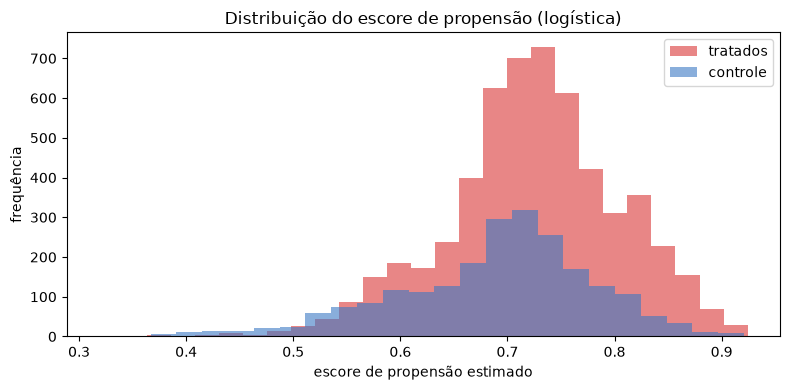

In [49]:
fig, ax = plt.subplots(figsize=(8, 4))
for grupo, cor, rotulo in [(1, "#d93636", "tratados"),
                           (0, "#3b78c3", "controle")]:
    ax.hist(dados.loc[dados["D"] == grupo, "pscore_logit"],
            bins=25, alpha=0.6, color=cor, label=rotulo)
ax.set_xlabel("escore de propensão estimado")
ax.set_ylabel("frequência")
ax.set_title("Distribuição do escore de propensão (logística)")
ax.legend()
plt.tight_layout();

ℹ️ Este gráfico é o diagnóstico de **suporte comum**.

- Onde as duas distribuições se sobrepõem, há comparação possível.
- Onde só existe uma cor, não há contrafactual
    - são as regiões problemáticas.

### Estimando o Escore por *Machine Learning* 🤖

👉 A turma é de ciência de dados e a tentação é imediata: 
- por que não usar um modelo mais complexo,
    - um *random forest*,
    - um *gradient boosting*,
- para estimar `e(X)`?

In [50]:
X_full = dados[COVARIAVEIS].values
d_full = dados["D"].values

Pode-se. Mas há **armadilhas sérias**, 
- e entendê-las é o ponto central deste bloco.

In [51]:
ps_logit_cv = cross_val_predict(
    LogisticRegression(max_iter=1000),
    X_full, d_full, cv=5, method="predict_proba")[:, 1]

In [52]:
print("escore logística — min/máx:", 
      round(ps_logit_cv.min(), 3),
      round(ps_logit_cv.max(), 3))

escore logística — min/máx: 0.323 0.933


In [53]:
ps_rf_cv = cross_val_predict(
    RandomForestClassifier(n_estimators=200, random_state=42),
    X_full, d_full, cv=5, method="predict_proba")[:, 1]

In [54]:
print("escore random forest — min/máx:",
      round(ps_rf_cv.min(), 3),
      round(ps_rf_cv.max(), 3))

escore random forest — min/máx: 0.005 1.0


🚨 **Primeira armadilha — escores extremos.** 
- O *random forest* produz escores muito mais próximos de 0 e de 1
    - do que a regressão logística.

Por quê? 
- Um modelo flexível "decora" o tratamento.
- Mas lembre da condição de **suporte comum**:
    - precisamos de `0 < e(X) < 1`.
- Escores em 0,99 e 0,01 são uma **violação prática de sobreposição**
    - e, como veremos, fazem o IPW explodir.

👉 **Segunda armadilha — predizer bem não é estimar bem.** 
- Vamos comparar a capacidade preditiva (AUC) dos dois escores.

In [55]:
auc_logit = roc_auc_score(d_full, dados["pscore_logit"])

In [56]:
auc_rf = roc_auc_score(d_full, ps_rf_cv)

In [57]:
pd.DataFrame({"modelo": ["logística", "random forest"],
              "AUC": [auc_logit, auc_rf]})

,modelo,AUC
0,logística,0.611106
1,random forest,0.538012


🚨 É tentador escolher o modelo de **maior AUC**. 
- **Não faça isso.**

O objetivo do escore de propensão **não é prever quem recebe o tratamento**. 
- É **equilibrar as covariáveis**
    - entre tratados e controles.

São objetivos diferentes:
- um AUC perto de 1,0 significa que
    - tratamento e controle são *perfeitamente distinguíveis*
        - ou seja, **não há sobreposição**, e o efeito causal não é estimável;
- o que queremos é um escore que,
    - ao ser usado para parear ou ponderar,
    - deixe as covariáveis **balanceadas**.

👉 O critério de qualidade do escore é 
- o **balanceamento** (próximo bloco),
- não a acurácia preditiva.

### Calibração: o Cuidado Essencial com ML

👉 Há ainda uma **terceira armadilha**. 

Para o escore funcionar como *probabilidade*, 
- ele precisa estar **calibrado**:
    - entre as crianças com escore 0,7,
    - aproximadamente 70% devem de fato ser tratadas.

🚨 Modelos como *random forest* **não produzem probabilidades calibradas** por padrão 
- eles tendem a empurrar as previsões para longe de 0 e 1 (ou o contrário). 

👉 Usar um escore mal calibrado num IPW gera pesos errados.

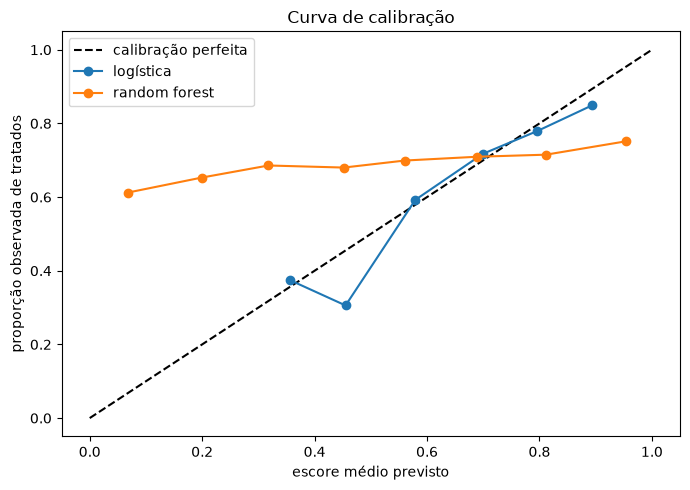

In [58]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], "k--", label="calibração perfeita")

for nome, escore in [("logística", ps_logit_cv),
                     ("random forest", ps_rf_cv)]:
    frac_pos, media_prev = calibration_curve(d_full, escore, n_bins=8)
    ax.plot(media_prev, frac_pos, "o-", label=nome)

ax.set_xlabel("escore médio previsto")
ax.set_ylabel("proporção observada de tratados")
ax.set_title("Curva de calibração")
ax.legend()
plt.tight_layout();

👉 A solução é **calibrar** o modelo de ML 
- (o `scikit-learn` faz isso com `CalibratedClassifierCV`.)

In [59]:
print("RF sem calibração — min/máx:",
      round(ps_rf_cv.min(), 3), round(ps_rf_cv.max(), 3))

RF sem calibração — min/máx: 0.005 1.0


In [60]:
# escore do RF calibrado, para uso posterior
ps_rf_cal_cv = cross_val_predict(
    CalibratedClassifierCV(
        RandomForestClassifier(n_estimators=200, random_state=42),
        method="isotonic", cv=5),
    X_full, d_full, cv=5, method="predict_proba")[:, 1]

In [61]:
print("RF calibrado — min/máx:",
      round(ps_rf_cal_cv.min(), 3),
      round(ps_rf_cal_cv.max(), 3))

RF calibrado — min/máx: 0.274 0.806


👉 Mas mudar o min/máx não basta
- precisamos **ver** se a curva de calibração de fato se aproximou da diagonal.

💡 Vamos replotá-la com as três versões.

ℹ️ Para uma comparação **justa**, 
- os três escores são avaliados *fora da amostra de treino* (validação cruzada).

Avaliar um modelo nos mesmos dados em que ele treinou superestima a calibração.

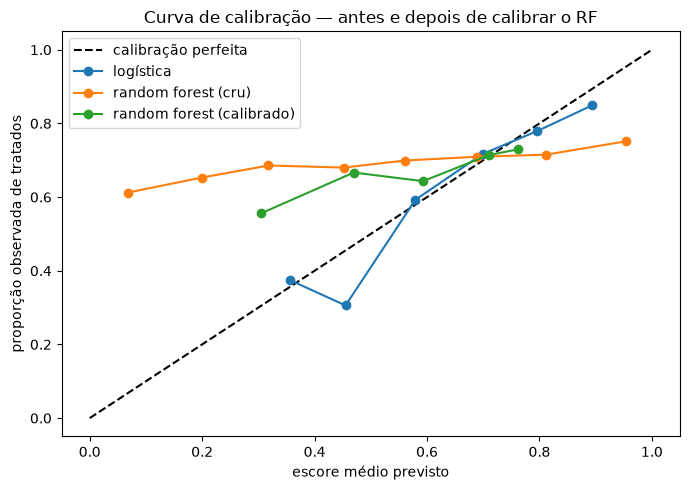

In [62]:
# os três escores, todos estimados out-of-fold (validação cruzada)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], "k--", label="calibração perfeita")

for nome, escore in [("logística", ps_logit_cv),
                     ("random forest (cru)", ps_rf_cv),
                     ("random forest (calibrado)", ps_rf_cal_cv)]:
    frac_pos, media_prev = calibration_curve(d_full, escore, n_bins=8)
    ax.plot(media_prev, frac_pos, "o-", label=nome)

ax.set_xlabel("escore médio previsto")
ax.set_ylabel("proporção observada de tratados")
ax.set_title("Curva de calibração — antes e depois de calibrar o RF")
ax.legend()
plt.tight_layout();

ℹ️ O escore calibrado é mais bem-comportado 
- menos valores extremos, probabilidades mais confiáveis.

🚨 A lição do bloco:
- ML pode estimar o escore de propensão,
- mas exige cuidados que um pipeline preditivo comum ignora
    - controlar *overfitting* (validação cruzada),
    - **calibrar** as probabilidades, e
    - nunca confundir AUC com qualidade causal.

### O Escore não é um Atributo da Família

A AIBF II nos dá uma oportunidade rara de checagem: 
- a equipe do **IFPRI** publicou os escores de propensão
    - que *ela* calculou na avaliação oficial do Bolsa Família. 

👉 Estão no arquivo `pscores_extrato.csv`.

Vamos comparar o escore que **nós** estimamos 
- com o escore **oficial**.

In [63]:
oficial = pd.read_csv("data/pscores_completo.csv")

In [64]:
comparacao = dados.merge(oficial[["cod_dtm", "pscore_tr1"]],
                         on="cod_dtm", how="left")
comparacao = comparacao.dropna(subset=["pscore_tr1"])

In [65]:
print("crianças com escore oficial:", len(comparacao))

crianças com escore oficial: 7453


In [66]:
corr = comparacao[["pscore_logit", "pscore_tr1"]].corr().iloc[0, 1]

In [67]:
print("correlação (nosso escore x escore oficial IFPRI):", round(corr, 3))

correlação (nosso escore x escore oficial IFPRI): 0.198


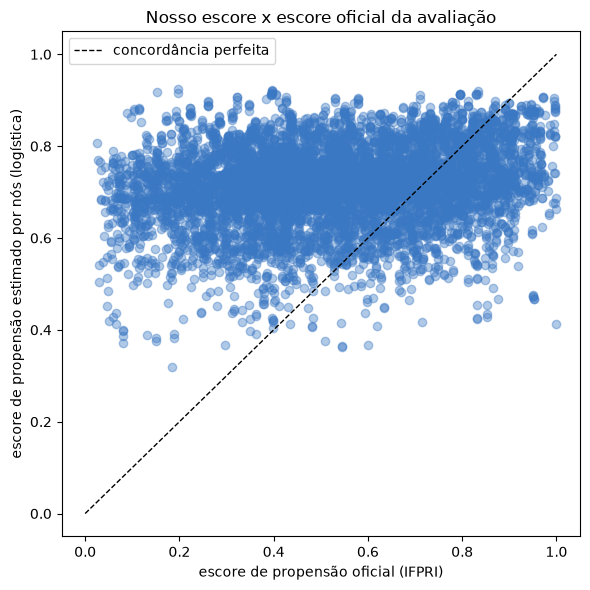

In [68]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(comparacao["pscore_tr1"], comparacao["pscore_logit"],
           alpha=0.4, color="#3b78c3")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="concordância perfeita")
ax.set_xlabel("escore de propensão oficial (IFPRI)")
ax.set_ylabel("escore de propensão estimado por nós (logística)")
ax.set_title("Nosso escore x escore oficial da avaliação")
ax.legend()
plt.tight_layout();

🚨 Os dois escores **mal se correlacionam** 
- a nuvem de pontos está longe da diagonal.

Como dois escores de propensão para 
- o *mesmo programa*,
- as *mesmas famílias*,

podem discordar tanto?

👉 Porque um escore de propensão **não é uma propriedade da família** 
- é uma propriedade do **desenho da avaliação**.

Ele depende de quatro escolhas, e a equipe do IFPRI fez escolhas diferentes das nossas:

- **A definição de tratamento.**
    - Nós definimos `D` por titularidade do cartão hoje;
    - o IFPRI trabalhou com a estrutura de painel 2005–2009 e
        - definições próprias de tratamento
        - (as colunas `tr1`, `tr2r2`, `tr3r2` do arquivo são *três* definições distintas).
- **As covariáveis.**
    - Usamos 7 covariáveis do extrato;
    - a avaliação oficial usou dezenas,
        - incluindo variáveis municipais.
- **A amostra.**
    - Recortamos crianças de 6–17 anos com desfecho observado;
    - o escore oficial foi calculado sobre outro recorte.
- **A rodada.**
    - Nossas covariáveis vêm de uma rodada;
    - o escore oficial incorpora a linha de base de 2005.

ℹ️ A prova definitiva está dentro do próprio arquivo oficial: 
- os escores `pscore_tr1` e `pscore_tr2r2`
    - ambos calculados pelo IFPRI, para o mesmo Bolsa Família,
- correlacionam **apenas 0,68** entre si,
    - porque correspondem a definições de tratamento diferentes.

🚨 **A lição.**

- Não existe "o" escore de propensão de uma família. 
- Existe o escore *de um desenho de avaliação*.
    - Trocar a definição de tratamento, 
    - o conjunto de covariáveis ou
    - a amostra
    - produz outro escore
        - e isso não é um erro, é a natureza do objeto.

👉 É mais uma razão para o critério de qualidade nunca ser "o escore está certo?" 
- não há um escore certo,
- e sim "o escore **equilibrou as covariáveis**?". 

O balanceamento, que veremos no próximo bloco, é o que se pode de fato verificar.

## Métodos Baseados no Escore: Pareamento, Estratos e IPW

👉 Com o escore estimado, 
- há três formas clássicas de usá-lo para estimar o efeito causal.

Vamos às três, com o escore da logística.

### 1. Pareamento pelo escore de propensão

👉 Em vez de parear em muitas covariáveis, 
- pareamos em **um número**: o escore.
    - Para cada tratado,
    - o controle de escore mais próximo.

In [69]:
ps = dados["pscore_logit"].values.reshape(-1, 1)
ps_trat = ps[dados["D"].values == 1]
ps_ctrl = ps[dados["D"].values == 0]

In [70]:
nn_ps = NearestNeighbors(n_neighbors=1).fit(ps_ctrl)
_, idx = nn_ps.kneighbors(ps_trat)

In [71]:
Y_trat = dados.loc[dados["D"] == 1, "Y"].values
Y_ctrl = dados.loc[dados["D"] == 0, "Y"].values

In [72]:
att_psm = np.mean(Y_trat - Y_ctrl[idx.flatten()])

In [73]:
print("ATT por pareamento pelo escore (PSM):", round(att_psm, 4))

ATT por pareamento pelo escore (PSM): -0.0097


### 2. Estratificação pelo Escore

👉 Dividimos a amostra em 5 blocos pelo escore e agregamos as diferenças
- (a subclassificação do Bloco 2, agora sobre o escore em vez de `X` cru.)

In [74]:
dados["bloco_ps"] = pd.qcut(dados["pscore_logit"], 5, labels=False)

linhas = []
for b in range(5):
    g = dados[dados["bloco_ps"] == b]
    if (g["D"] == 1).any() and (g["D"] == 0).any():
        dif = (g.loc[g["D"] == 1, "Y"].mean()
               - g.loc[g["D"] == 0, "Y"].mean())
        linhas.append({"bloco": b, "n": len(g), "dif": dif})

tab_blocos = pd.DataFrame(linhas)

In [75]:
print(tab_blocos)

   bloco     n       dif
0      0  1561 -0.013955
1      1  1561 -0.005415
2      2  1561 -0.004965
3      3  1561 -0.007885
4      4  1561 -0.001887


In [76]:
ate_estrat = np.average(tab_blocos["dif"], weights=tab_blocos["n"])

In [77]:
print("ATE por estratificação no escore:", round(ate_estrat, 4))

ATE por estratificação no escore: -0.0068


### 3. Ponderação pelo Inverso da Probabilidade (IPW) ⚖️

👉 A terceira via não pareia nem estratifica:
- **repondera** a amostra.

A intuição: 
- um tratado com escore baixo
    - (era "improvável" que fosse tratado)
    - é **raro** e recebe **peso alto**;
- um controle com escore alto, idem. 

A ponderação reconstrói o equilíbrio que um experimento teria dado.

O estimador **IPW** do efeito médio:

$$\widehat{ATE}_{IPW} = \frac{1}{n}\sum_{i}
\left[ \frac{D_i \, Y_i}{e(X_i)}
- \frac{(1-D_i)\, Y_i}{1 - e(X_i)} \right]$$

In [78]:
e = dados["pscore_logit"].values
D = dados["D"].values
Y = dados["Y"].values

In [79]:
peso = np.where(D == 1, 
                1 / e,
                1 / (1 - e))

In [80]:
ate_ipw = (np.average(Y[D == 1], weights=peso[D == 1])
           - np.average(Y[D == 0], weights=peso[D == 0]))

In [81]:
print("ATE por IPW:", round(ate_ipw, 4))

ATE por IPW: -0.0066


🚨 O ponto frágil do IPW está na fórmula: 
- dividimos por `e(X)` e por `1 − e(X)`.

Se o escore for muito próximo de 0 ou 1 
- o **peso explode** e uma única observação domina a estimativa.

👉 exatamente o que o ML descalibrado produz,

Por isso o cuidado com escores extremos não é teórico: 
- é o que quebra o IPW na prática.

👉 Vamos reunir as estimativas dos três métodos e 
- comparar com a diferença ingênua.

In [82]:
resumo = pd.DataFrame({
    "método": ["diferença simples", "subclassificação (X)",
               "pareamento por vizinho", "pareamento pelo escore",
               "estratificação no escore", "IPW"],
    "estimativa": [dif_simples, ate_subclass, att_nn,
                   att_psm, ate_estrat, ate_ipw],
})

In [83]:
resumo

,método,estimativa
0,diferença simples,-0.006315
1,subclassificação (X),-0.005319
2,pareamento por vizinho,-0.008015
3,pareamento pelo escore,-0.009727
4,estratificação no escore,-0.006821
5,IPW,-0.006612


ℹ️ Os métodos de ajuste deslocam a estimativa em relação à diferença ingênua. 
- Nenhum é "a verdade"
    - todos dependem da **mesma** hipótese de ignorabilidade.
- Mas, *se* ela valer, são estimativas bem mais críveis do que a comparação bruta.

## Diagnósticos e a Crítica ao Pareamento pelo Escore

### O Balanceamento é o Verdadeiro Critério

👉 Como saber se o ajuste **funcionou**? 

- Não se olha o AUC do escore.
- Olha-se se as **covariáveis ficaram equilibradas** entre tratados e controles depois do ajuste.

A métrica é a **diferença padronizada de médias** (*standardized mean difference*, SMD).

- Regra prática: `|SMD| < 0,1` indica bom balanceamento.

👉 Calculamos o SMD de cada covariável **antes** do ajuste.

In [84]:
linhas = []
for v in COVARIAVEIS:
    x1 = dados.loc[dados["D"] == 1, v]
    x0 = dados.loc[dados["D"] == 0, v]
    sd = np.sqrt((x1.var() + x0.var()) / 2)
    smd = (x1.mean() - x0.mean()) / sd if sd > 0 else 0.0
    linhas.append({"covariável": v, "SMD": smd})
smd_antes = pd.DataFrame(linhas)

In [85]:
smd_antes

,covariável,SMD
0,s02af,-0.035474
1,feminino,0.036990
2,educ_chefe,-0.278771
3,n_moradores,0.221699
4,n_comodos,-0.133783
5,n_dormitorios,-0.081991
6,agua,-0.224046


👉 E **depois** do ajuste por IPW 
- recalculando as médias ponderadas pelos pesos do escore.

In [86]:
linhas = []
for v in COVARIAVEIS:
    m1 = dados.loc[dados["D"] == 1, v]
    m0 = dados.loc[dados["D"] == 0, v]
    w1 = peso[dados["D"].values == 1]
    w0 = peso[dados["D"].values == 0]
    media1 = np.average(m1, weights=w1)
    media0 = np.average(m0, weights=w0)
    sd = np.sqrt((m1.var() + m0.var()) / 2)
    smd = (media1 - media0) / sd if sd > 0 else 0.0
    linhas.append({"covariável": v,
                   "SMD": smd})
smd_depois = pd.DataFrame(linhas)

In [87]:
smd_depois

,covariável,SMD
0,s02af,0.006310
1,feminino,-0.009247
2,educ_chefe,0.002193
3,n_moradores,-0.021929
4,n_comodos,0.001465
5,n_dormitorios,0.004959
6,agua,0.005921


👉 O **love plot** compara os dois: 
- a fotografia do antes e depois.

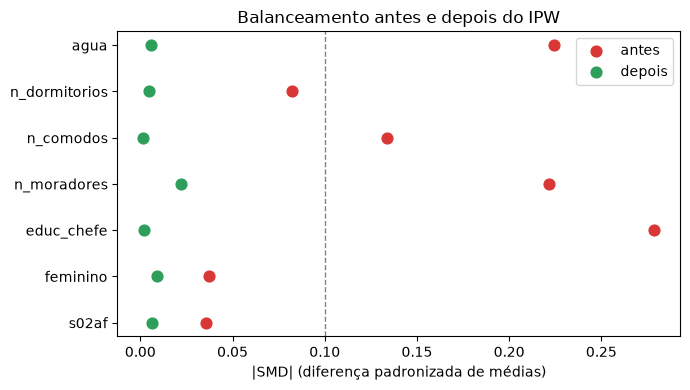

In [88]:
love_plot(smd_antes, smd_depois,
          titulo="Balanceamento antes e depois do IPW")

ℹ️ O efeito do IPW aqui é nítido: 
- covariáveis que partiam de um forte desbalanceamento
    - escolaridade do chefe,
    - número de moradores e
    - acesso a água
- tinham |SMD| entre 0,22 e 0,28
    - terminam praticamente zeradas (|SMD| < 0,03) depois da ponderação. 

Os pontos verdes colapsam sobre o zero.

🚨 **Este** é o diagnóstico que importa 
- não a capacidade preditiva do escore. 

Um escore que equilibra as covariáveis cumpriu seu papel, 
- independentemente do seu AUC.

### Extra! 🗞️ A crítica ao Pareamento pelo Escore

👉 Um debate importante na literatura recente.
- King & Nielsen (2019) argumentam que
    - **parear pelo escore de propensão pode ser contraproducente**.

O argumento: 
- ao aproximar pares pelo escore — um único número —,
- pode-se acabar emparelhando crianças com escores iguais
    - mas **covariáveis bem diferentes**
    - (afinal, perfis distintos podem ter a mesma probabilidade de tratamento).

Em certos casos, 
- isso **aumenta** o desbalanceamento,
- em vez de reduzir.

ℹ️ A recomendação dos autores é preferir 
- pareamento direto nas covariáveis
    - (distância de Mahalanobis, *coarsened exact matching*)
- ao pareamento pelo escore.

🚨 Atenção ao escopo da crítica: 
- ela é dirigida ao **pareamento** pelo escore. 

A **estratificação** pelo escore e o **IPW** não são alvo do argumento e 
- seguem sendo ferramentas válidas.

É um ponto de debate vivo 
- não um veredito fechado.

## Extra! 🗞️ Estimadores Duplamente Robustos

👉 Vimos duas famílias de métodos: 
- as que modelam **quem recebe o tratamento** (o escore) e
    - implicitamente, na regressão,
- as que modelam **o desfecho**. 

Surge uma pergunta natural: 
- e se combinarmos as duas?

Um **estimador duplamente robusto** (*doubly robust*, ou AIPW) 
- junta um modelo do escore `e(X)` com
- um modelo do desfecho. 

A propriedade que dá nome ao método:

> O estimador é consistente se **pelo menos um** dos dois modelos estiver corretamente especificado
> - não é preciso acertar os dois.

ℹ️ É uma forma de **seguro**: 
- se o modelo do escore estiver errado mas o do desfecho estiver certo
    - (ou vice-versa),
    - a estimativa ainda é válida.
- Os métodos modernos de *machine learning causal*
    - (que não vemos no curso)
- são construídos sobre essa ideia.

## Síntese e Próximo Módulo 🎯

👉 O que levamos desta aula:

- Sem sorteio,
    - é possível estimar efeitos causais **sob a hipótese de ignorabilidade**:
        - o tratamento é "como se" aleatório dentro de estratos de `X`.
- A **subclassificação** e o **pareamento** comparam perfis semelhantes,
    - mas sofrem com a **maldição da dimensionalidade**.
- O **escore de propensão** resume `X` num único número (Rosenbaum & Rubin) e
    - habilita pareamento,
    - estratificação e
    - **IPW**.

- O escore pode ser estimado por **logística** ou por **ML**
    - mas ML exige cuidado com
        - *overfitting*,
        - escores extremos e
        - **calibração**.
    - AUC alto não é o objetivo;
    - **balanceamento** é.
- O diagnóstico que importa é o **balanceamento das covariáveis**
    - (SMD, love plot),
    - não a capacidade preditiva.

🚨 **A limitação fundamental.**

Tudo nesta aula depende da **ignorabilidade**: 
- a hipótese, não testável,
    - de que `X` contém todos os confundidores.

Diferente do RCT do Módulo 02, 
- estes métodos **não resolvem o viés de variáveis omitidas**.

Se existe um confundidor não observado,
- a motivação dos pais, por exemplo, 
- nenhum pareamento ou escore o corrige.

Pareamento equilibra o que se **mede**;
- sobre o que não se mede,
    - é cego.

👉 Uma forma de organizar as ferramentas do curso, 
- da mais para a menos crível em termos de identificação:
    - RCT (Módulo 02) $\Rightarrow$ 
    - Variáveis instrumentais $\Rightarrow$
    - Diferenças-em-diferenças $\Rightarrow$ 
    - Regressão descontínua $\Rightarrow$ 
    - Seleção nos observáveis (esta aula).

Cada degrau abaixo do RCT 
- troca uma garantia por uma **hipótese**.

👉 **Para casa.**

1. Vimos que o escore `pscore_tr1` do IFPRI mal se correlaciona com o nosso.
    - O arquivo `pscores_completo.csv` traz uma segunda definição oficial:
        - `pscore_tr2r2`.
    - Compare-a, num gráfico de dispersão, com o nosso escore
        - e com o `pscore_tr1`.
    - O que a comparação entre as duas definições oficiais sugere?
2. Reestime o efeito do Bolsa Família por IPW
    - usando o escore do **gradient boosting** (`GradientBoostingClassifier`),
        - com e sem calibração.
    - O resultado muda? Por quê?
3. Faça o love plot do pareamento pelo escore
    - e compare com o do IPW.
    - Qual equilibrou melhor as covariáveis?

#### Saiba Mais 👩‍🏫

👉 Para se aprofundar em pareamento e escore de propensão:

- FACURE, M. *<a href="https://matheusfacure.github.io/python-causality-handbook/">Causal Inference for the Brave and True</a>* — caps. 11 (*Propensity Score*) e 12 (*Doubly Robust Estimation*).
- CUNNINGHAM, S. *<a href="https://mixtape.scunning.com/05-matching_and_subclassification">Causal Inference: The Mixtape</a>* — cap. 5 (*Matching and Subclassification*).
- Documentação do `scikit-learn` sobre <a href="https://scikit-learn.org/stable/modules/calibration.html">calibração de probabilidades</a>.

👉 **Executem todo este caderno** antes da próxima aula e tragam dúvidas. 🚀